In [12]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tqdm.keras import TqdmCallback

print("TensorFlow version :", tf.__version__)

# Chargement des tenseurs globaux (ceux que tu as générés)
X_complet = np.load('X_dataset.npy')
Y_complet = np.load('Y_dataset.npy')
from sklearn.utils import shuffle

# On mélange X et Y de la même façon (random_state=42 garantit le même mélange à chaque fois)
X_complet, Y_complet = shuffle(X_complet, Y_complet, random_state=42)


# Découpage direct dans Colab (80% apprentissage, 20% test)
print(" Découpage des données en cours...")
X_train, X_test, Y_train, Y_test = train_test_split(X_complet, Y_complet, test_size=0.2, random_state=42, shuffle=True)

# On calcule dynamiquement les dimensions pour que l'IA s'adapte à ton jeu de données
nb_echantillons, nb_pas_de_temps, nb_capteurs = X_train.shape
nb_classes = len(np.unique(Y_complet))

print(f" Données chargées et découpées avec succès !")
print(f"   Dataset complet : {X_complet.shape[0]} fenêtres")
print(f"   X_train (Apprentissage) : {X_train.shape} ")
print(f"   X_test (Validation)     : {X_test.shape} ")
print(f"   Classes détectées : {nb_classes}")

TensorFlow version : 2.20.0
 Découpage des données en cours...
 Données chargées et découpées avec succès !
   Dataset complet : 1410 fenêtres
   X_train (Apprentissage) : (1128, 200, 6) 
   X_test (Validation)     : (282, 200, 6) 
   Classes détectées : 11


In [8]:

model = Sequential([
    # 1er Bloc Convolutif : Le "Détective" de base (cherche des petits pics)
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(nb_pas_de_temps, nb_capteurs)),
    MaxPooling1D(pool_size=2), # Réduit la taille pour ne garder que le plus important

    # 2ème Bloc Convolutif : Le "Détective" avancé (assemble les pics pour voir des vagues)
    Conv1D(filters=128, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),

    # Écrasement : On transforme le résultat 2D en une simple ligne de données
    Flatten(),

    # Le Cerveau de décision (Réseau classique)
    Dense(128, activation='relu'),

    # Dropout : On "désactive" 50% des neurones au hasard pour forcer l'IA à
    # ne pas apprendre par coeur (empêche l'Overfitting)
    Dropout(0.5),

    # Couche de sortie : Autant de neurones que d'exercices.
    # Softmax transforme les valeurs en pourcentages (ex: 95% Squat, 5% Repos)
    Dense(nb_classes, activation='softmax')
])

# Compilation du modèle
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # Idéal quand Y contient des entiers (0, 1, 2...)
    metrics=['accuracy']
)

print(" Architecture du modèle CNN 1D :")
model.summary()


 Architecture du modèle CNN 1D :


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 198, 64)        │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 99, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 97, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       786,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,899 (3.10 MB)

 Trainable params: 813,899 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    Y_train,
    epochs=25,
    batch_size=32,
    validation_data=(X_test, Y_test),
    verbose=0, # On désactive l'affichage moche par défaut de Keras
    callbacks=[TqdmCallback(verbose=1)] # On ajoute la magnifique barre de progression Tqdm !
)

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]


🏆 Précision finale sur les données de Test : 100.00%


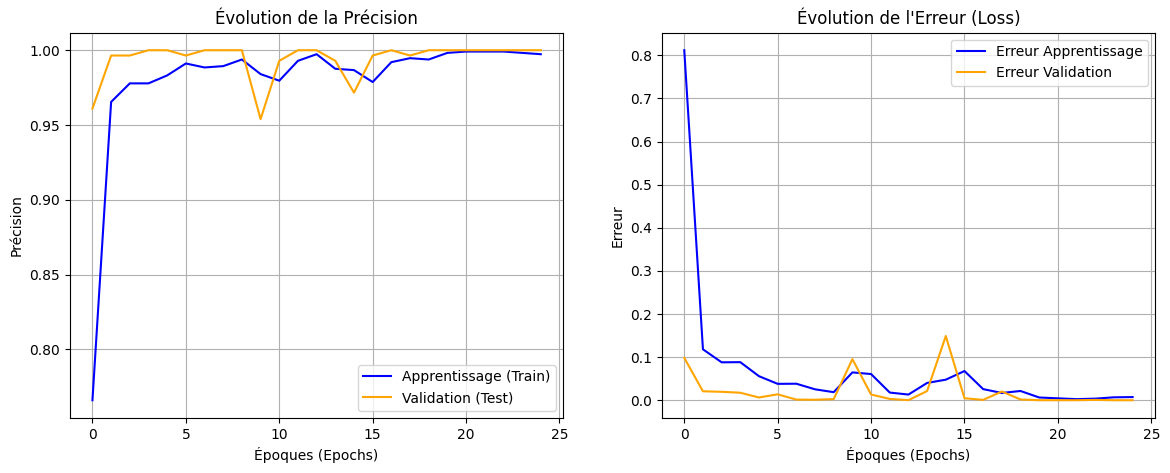

In [10]:
loss, accuracy = model.evaluate(X_test, Y_test, verbose=0)
print(f" Précision finale sur les données de Test : {accuracy * 100:.2f}%")

# 2. Affichage des courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique de la Précision (Accuracy)
ax1.plot(history.history['accuracy'], label='Apprentissage (Train)', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation (Test)', color='orange')
ax1.set_title('Évolution de la Précision')
ax1.set_xlabel('Époques (Epochs)')
ax1.set_ylabel('Précision')
ax1.legend()
ax1.grid(True)

# Graphique de l'Erreur (Loss)
ax2.plot(history.history['loss'], label='Erreur Apprentissage', color='blue')
ax2.plot(history.history['val_loss'], label='Erreur Validation', color='orange')
ax2.set_title("Évolution de l'Erreur (Loss)")
ax2.set_xlabel('Époques (Epochs)')
ax2.set_ylabel('Erreur')
ax2.legend()
ax2.grid(True)

plt.show()

In [11]:
model.save('modele_trackwatch_cnn.h5')
